In [1]:
print("CodeNova AI/ML Internship")
print("Task 1: Exploratory Data Analysis")
print("Created by: Mrunal Anand Bhogade")

CodeNova AI/ML Internship
Task 1: Exploratory Data Analysis
Created by: Mrunal Anand Bhogade


In [2]:

import pandas as pd

df = pd.read_csv("data/archive/train.csv")

df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:

print("Dataset loaded successfully!")

print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset loaded successfully!
Number of rows and columns: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [4]:
df.shape


(891, 12)

In [5]:
df.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'Embarked']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [7]:

print("Missing values in each column:")

print(df.isnull().sum())


Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [8]:

print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


In [9]:

#  Create a copy of the original dataset

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)
print("Dataset copy created successfully!")


Original dataset shape: (891, 12)
Clean dataset shape: (891, 12)
Dataset copy created successfully!


In [10]:

# Check missing values in the copied dataset

missing_values = df_clean.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])


Missing values in each column:
Age         177
Cabin       687
Embarked      2
dtype: int64


In [11]:

#  Clean missing values

# Fill missing ages with the median
df_clean["Age"] = df_clean["Age"].fillna(
    df_clean["Age"].median()
)

# Fill missing embarkation ports with the most common value
df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

# Drop Cabin because it contains many missing values
df_clean = df_clean.drop(columns=["Cabin"])

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nNew dataset shape:", df_clean.shape)


Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

New dataset shape: (891, 11)


In [12]:

# Check duplicate rows after cleaning

print("Duplicate rows:", df_clean.duplicated().sum())


Duplicate rows: 0


In [13]:

#  Import visualization libraries

import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization libraries imported successfully!")


Visualization libraries imported successfully!


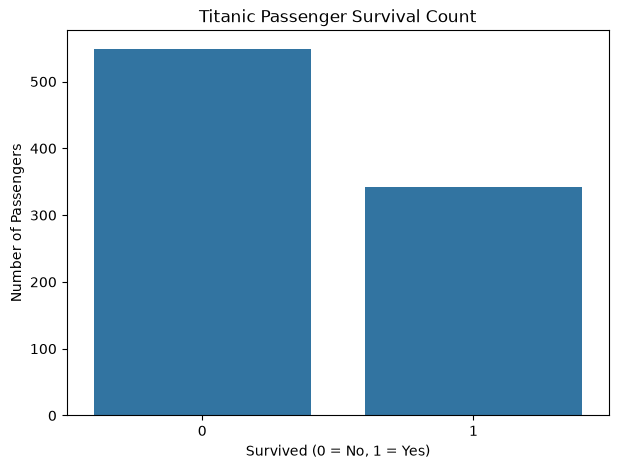

In [14]:

#  Plot passenger survival counts

plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Survived")

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()


In [15]:

#  Calculate survival percentages

survival_counts = df_clean["Survived"].value_counts()

print("Survival counts:")
print(survival_counts)

print("\nSurvival percentage:")
print((df_clean["Survived"].value_counts(normalize=True) * 100).round(2))


Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentage:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


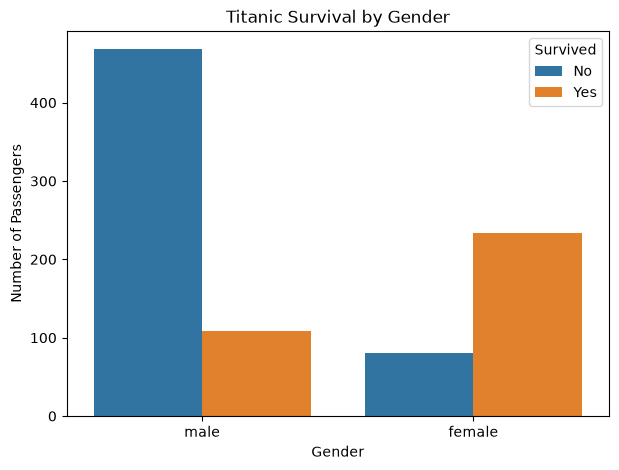

In [16]:

#  Compare survival by gender

plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Sex", hue="Survived")

plt.title("Titanic Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.legend(title="Survived", labels=["No", "Yes"])

plt.show()


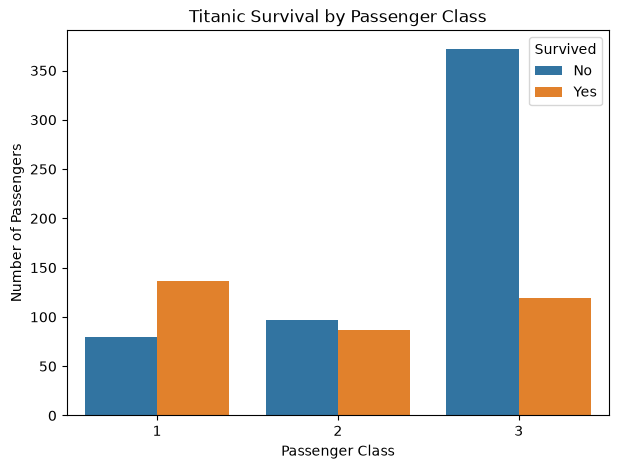

In [17]:

# Compare survival by passenger class

plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Pclass", hue="Survived")

plt.title("Titanic Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.legend(title="Survived", labels=["No", "Yes"])

plt.show()


In [18]:

#  Save the cleaned dataset

df_clean.to_csv("../cleaned_titanic.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [19]:

import os

print("Current working folder:")
print(os.getcwd())


Current working folder:
C:\Users\mruna\CodeNova_AI_ML\Task1_EDA


In [20]:

#  Calculate survival rate by gender

gender_survival = df_clean.groupby("Sex")["Survived"].mean() * 100

print("Survival rate by gender:")
print(gender_survival.round(2))


Survival rate by gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


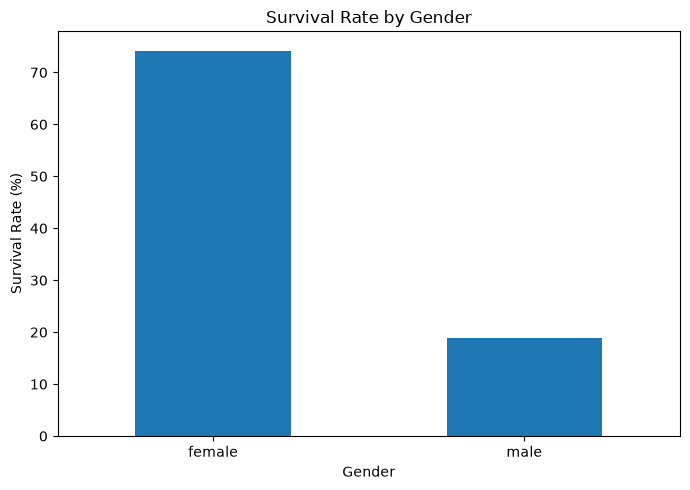

In [21]:

# Plot survival rate by gender

gender_survival.plot(kind="bar", figsize=(7, 5))

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [22]:

#  Calculate survival rate by passenger class

class_survival = (
    df_clean.groupby("Pclass")["Survived"].mean() * 100
)

print("Survival rate by passenger class:")
print(class_survival.round(2))


Survival rate by passenger class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


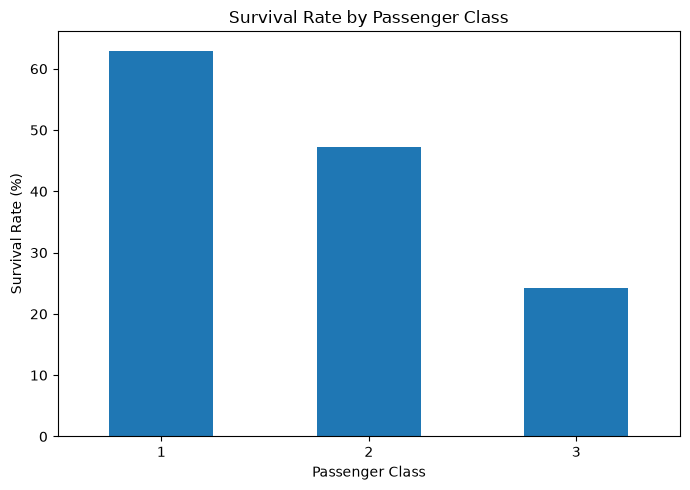

In [23]:

#  Visualize survival rate by passenger class

class_survival.plot(kind="bar", figsize=(7, 5))

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Age summary:
count    891.000000
mean      29.361582
std       13.019697
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       80.000000
Name: Age, dtype: float64


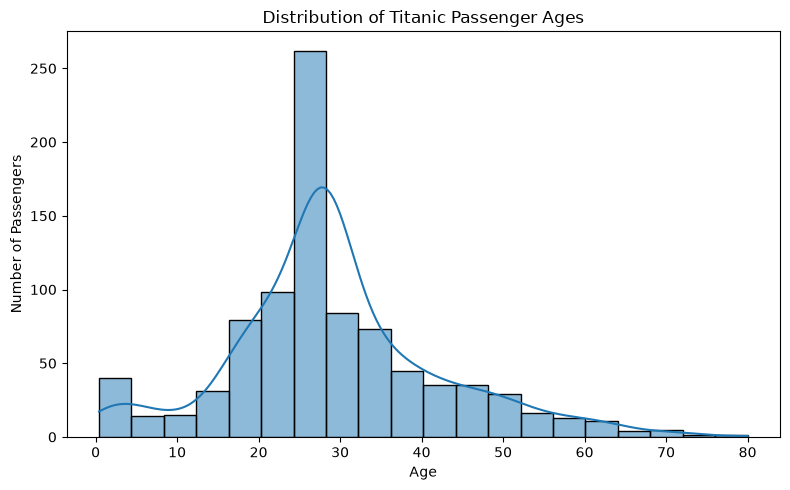

In [24]:

#  Explore passenger age distribution

print("Age summary:")
print(df_clean["Age"].describe())

plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Age", bins=20, kde=True)

plt.title("Distribution of Titanic Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


Correlation with survival:
Survived       1.000000
Fare           0.257307
Parch          0.081629
PassengerId   -0.005007
SibSp         -0.035322
Age           -0.064910
Pclass        -0.338481
Name: Survived, dtype: float64


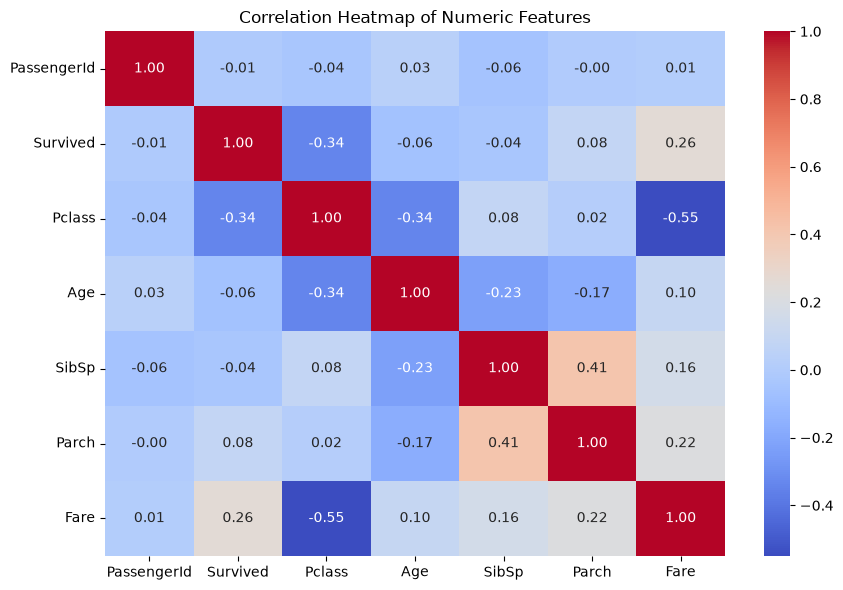

In [25]:

#  Calculate correlations for numeric columns

numeric_df = df_clean.select_dtypes(include="number")

correlation = numeric_df.corr()

print("Correlation with survival:")
print(correlation["Survived"].sort_values(ascending=False))

plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()


In [25]:

# Recreate the gender survival rate variable

gender_survival = (
    df_clean.groupby("Sex")["Survived"].mean() * 100
)

print("Survival rate by gender:")
print(gender_survival.round(2))


Survival rate by gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


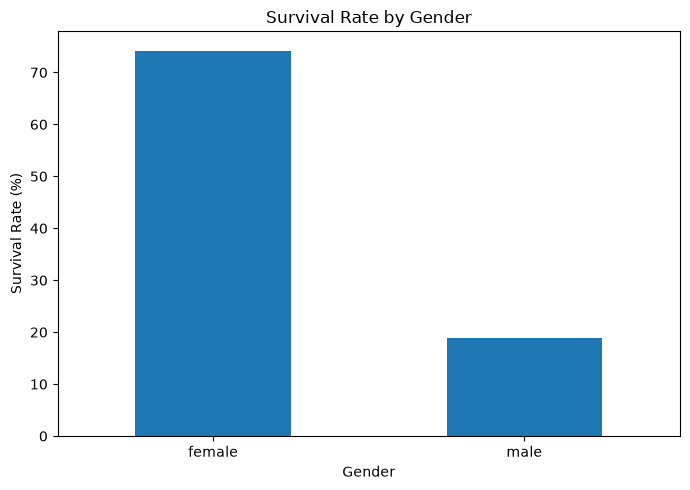

Graph saved successfully!


In [26]:


#  Save the gender survival graph

plt.figure(figsize=(7, 5))
gender_survival.plot(kind="bar")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("survival_rate_by_gender.png", dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved successfully!")


In [27]:

import os

print(os.getcwd())


C:\Users\mruna\CodeNova_AI_ML\Task1_EDA


In [28]:

import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in this directory:")
print(os.listdir())


Current working directory:
C:\Users\mruna\CodeNova_AI_ML\Task1_EDA

Files in this directory:
['.ipynb_checkpoints', 'data', 'outputs', 'README.md', 'survival_rate_by_gender.png', 'Task1_Exploratory_Data_Analysis.ipynb', 'Task1_Titanic_EDA_Report.docx', 'Task1_Titanic_EDA_Report.pdf', '~$sk1_Titanic_EDA_Report.docx']


In [29]:

# Create an outputs folder if it does not exist

os.makedirs("outputs", exist_ok=True)

print("Outputs folder is ready!")


Outputs folder is ready!


In [30]:

# Save the cleaned dataset

df_clean.to_csv("outputs/cleaned_titanic.csv", index=False)

print("Cleaned dataset saved!")


Cleaned dataset saved!


In [32]:
# Calculate survival rate by gender
gender_survival = (
    df_clean.groupby("Sex")["Survived"].mean() * 100
)

# Calculate survival rate by passenger class
class_survival = (
    df_clean.groupby("Pclass")["Survived"].mean() * 100
)

# Display both results
print("Survival rate by gender:")
print(gender_survival.round(2))

print("\nSurvival rate by passenger class:")
print(class_survival.round(2))

Survival rate by gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival rate by passenger class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


In [34]:

# Save the survival rate by gender graph

plt.figure(figsize=(7, 5))
gender_survival.plot(kind="bar")
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/survival_rate_by_gender.png", dpi=300)
plt.close()

# Save the survival rate by passenger class graph

plt.figure(figsize=(7, 5))
class_survival.plot(kind="bar")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/survival_rate_by_class.png", dpi=300)
plt.close()

# Save the passenger age distribution graph

plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Age", bins=20, kde=True)
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.savefig("outputs/passenger_age_distribution.png", dpi=300)
plt.close()

print("Three graphs saved successfully!")


Three graphs saved successfully!


In [32]:

print("Files inside outputs:")

for filename in os.listdir("outputs"):
    print(filename)


Files inside outputs:
cleaned_titanic.csv
passenger_age_distribution.png
survival_rate_by_class.png
survival_rate_by_gender.png
